# MLM feature tour

One notebook that shows every feature of MLM, each with a short explanation and a small,
fast example (the whole notebook runs in about two minutes):

| § | Feature |
|---|---|
| 1 | Reading layers: POSCAR (any variant) and CIF |
| 2 | A bilayer search; the fast scanner vs the reference `match.py` |
| 3 | N-layer stacks: tournament tree, a twist window per interface, dry run, run metadata |
| 4 | Parallel searches |
| 5 | Stop and resume a run |
| 6 | Jumping to structures: index, `find`, `get`, `lineage`; SQLite index |
| 7 | Lifting `match.scan`'s limits: axis points and the per-angle cap |
| 8 | Merging symmetry-equivalent twists |
| 9 | Heterostructures: rigid vs strained, strain modes, strain sharing, elastic constants |
| 10 | Building structures: VASP/LAMMPS, sanity checks, layer shifts, Poisson, 3D view |
| 11 | Recipes, schema versions and reproducibility; the command line |
| 12 | The graphical interface |

**Before running:** `pip install -e ".[gui,checks]"` in the repository (once per environment).
Everything this notebook writes goes to `runs/feature_tour/`.

**Angle convention:** a twist is the anticlockwise rotation of a layer relative to the layer
directly below it.

## 0. Setup

In [1]:
import os
os.environ["TQDM_DISABLE"] = "1"   # hide match.py's progress bars

import shutil
import time
from dataclasses import replace
from pathlib import Path

import numpy as np
import pandas as pd
import yaml

import MLM


def find_repo_root(start=Path.cwd()):
    for folder in [start, *start.parents]:
        if (folder / "moire_structures").is_dir():
            return folder
    raise FileNotFoundError("run this notebook inside the MLM repository")


os.chdir(find_repo_root())   # all paths below are relative to the repository root
TOUR = Path("runs/feature_tour")
shutil.rmtree(TOUR, ignore_errors=True)
TOUR.mkdir(parents=True)
pd.set_option("display.width", 160)
print("MLM", MLM.__version__, "| working directory:", Path.cwd())

MLM 0.2.0 | working directory: /home/user/Multi-Layer-Moire-Generator-MLM


## 1. Reading layers

A layer is a primitive cell in a POSCAR (Cartesian or Direct coordinates, any scale factor,
Selective Dynamics) or a CIF; it is read with ASE (`MLM.io`). `MoireStructure.from_poscar`
turns it into a level-0 *recipe*: lattice vectors and metadata, no atoms.

In [2]:
from MLM.io import read_structure
from MLM.structure import MoireStructure

LAYER_FILES = {
    "bto": "moire_structures/bto/bto_1-layer.vasp",
    "graphene": "moire_structures/graphene/graphene_monolayer.vasp",
    "pto": "moire_structures/PTO_STO/pto_tetra_monolayer.vasp",
    "sto": "moire_structures/PTO_STO/STO_centered_unit_cell_cubic_monolayer.vasp",
}
roots = {label: MoireStructure.from_poscar(path, label) for label, path in LAYER_FILES.items()}
pd.DataFrame([{"label": label, "id": r.id, "formula": read_structure(LAYER_FILES[label]).get_chemical_formula(),
               "|a1| (Å)": round(float(np.linalg.norm(r.lattice_vectors[0])), 4),
               "|a2| (Å)": round(float(np.linalg.norm(r.lattice_vectors[1])), 4),
               "angle (deg)": round(r.angle_between_vectors, 2)} for label, r in roots.items()])

,label,id,formula,|a1| (Å),|a2| (Å),angle (deg)
0,bto,bto_1_406932,Ba2O4Ti,3.9904,3.9904,90.0
1,graphene,graphene_1_5977bc,C2,2.4673,2.4673,120.0
2,pto,pto_1_e344d9,O4Pb2Ti,3.8796,3.8796,90.0
3,sto,sto_1_6bab52,O4Sr2Ti,3.9127,3.9127,90.0


In [3]:
# The same layer as a CIF file gives the same recipe lattice.
from ase.io import write

write(TOUR / "bto.cif", read_structure(LAYER_FILES["bto"]), format="cif")
bto_from_cif = MoireStructure.from_poscar(TOUR / "bto.cif", "bto")
print("CIF lattice equals POSCAR lattice:",
      np.allclose(bto_from_cif.lattice_vectors, roots["bto"].lattice_vectors, atol=1e-6))

CIF lattice equals POSCAR lattice: True


## 2. A bilayer search, and the fast scanner

`find_candidates(lower, upper, params)` sweeps the twist of the upper layer and returns every
commensurate cell (equivalent descriptions merged). The default `scanner="fast"` is a
vectorised version of `match.py`; `scanner="match"` calls `match.py` itself. They return the
same cells.

In [4]:
from MLM.search import SearchParams, find_candidates

bto = roots["bto"]
params = SearchParams(degmin=1.0, degmax=45.0, degstep=0.01, nmin=-10, nmax=10, goodangles=(90.0,))

started = time.perf_counter()
cells = find_candidates(bto, bto, params)
fast_s = time.perf_counter() - started
started = time.perf_counter()
reference = find_candidates(bto, bto, replace(params, scanner="match"))
match_s = time.perf_counter() - started

print(f"fast scanner: {len(cells)} cells in {fast_s:.2f} s | match.py: {len(reference)} cells in {match_s:.2f} s")
print("identical results:", [c.id for c in cells] == [c.id for c in reference])
pd.DataFrame([{"twist (deg)": round(c.twist, 3), "residual (Å)": c.residual, "cell area (Å²)": round(c.cell_area, 1),
               "n (lower coefficients)": c.coefficients["lower"]} for c in cells]).head(8)

fast scanner: 19 cells in 0.27 s | match.py: 19 cells in 5.88 s
identical results: True


,twist (deg),residual (Å),cell area (Å²),n (lower coefficients)
0,6.73,0.002450,2308.9,"[[-9, 8], [-8, -9]]"
1,7.63,0.001370,1799.3,"[[-8, 7], [-7, -8]]"
2,8.80,0.001663,1353.5,"[[-7, 6], [-6, -7]]"
3,10.39,0.000621,971.3,"[[-6, 5], [-5, -6]]"
4,11.42,0.000830,1608.2,"[[-10, -1], [1, -10]]"
5,12.68,0.000171,652.8,"[[-5, 4], [-4, -5]]"
6,14.25,0.000018,1035.0,"[[-8, -1], [1, -8]]"
7,16.26,0.000071,398.1,"[[-4, 3], [-3, -4]]"


## 3. N-layer stacks

`build_stack` combines layers in a *tournament tree*: round 1 joins (L1+L2), (L3+L4), …; later
rounds join the resulting blocks. Every merge sets exactly one interface (layer k | layer k+1),
so each interface gets its own twist window via `SearchSchedule(..., interfaces={k: ...})`.
Rounds ≥ 2 combine moiré cells, which needs a larger coefficient range (`rounds={2: ...}`).

The dry run shows the work before anything is searched.

In [5]:
from MLM.search import Filters, SearchSchedule, build_stack

four_layers = [bto] * 4
schedule4 = SearchSchedule(
    SearchParams(nmin=-10, nmax=10, goodangles=(90.0,)),
    rounds={2: {"nmin": -10, "nmax": 10}},
    interfaces={1: {"degmin": 22.0, "degmax": 23.0},     # L1 | L2
                2: {"degmin": 30.0, "degmax": 31.0},     # L2 | L3 (joined in round 2)
                3: {"degmin": 36.5, "degmax": 37.5}},    # L3 | L4
)
_ = build_stack(four_layers, schedule4, dry_run=True)

DRY RUN — nothing searched
round 1: L1 + L2 -> L1-2, L3 + L4 -> L3-4
round 2: L1-2 + L3-4 -> L1-4
round 1: L1 + L2 -> L1-2: 1 x 1 = 1 searches
round 1: L3 + L4 -> L3-4: 1 x 1 = 1 searches
round 2: L1-2 + L3-4 -> L1-4: ? x ? = ? searches (known once the previous round has run)


In [6]:
four = build_stack(four_layers, schedule4, Filters(max_residual=1e-3), run_dir=TOUR / "bto_4layer", log=None)
print(four.summary())
best = four.final[0]
print("\nlayer orientations (deg):", np.round(best.layer_rotations, 3))
print("twist per interface (deg):", np.round(np.diff(best.layer_rotations), 3))

run directory: runs/feature_tour/bto_4layer
round 1: L1 + L2 -> L1-2, L3 + L4 -> L3-4
round 2: L1-2 + L3-4 -> L1-4
round 1: L1 + L2 -> L1-2: 1 x 1 = 1 searches -> 1 candidates, 1 passed filters (0.0 s)
round 1: L3 + L4 -> L3-4: 1 x 1 = 1 searches -> 1 candidates, 1 passed filters (0.0 s)
round 2: L1-2 + L3-4 -> L1-4: 1 x 1 = 1 searches -> 1 candidates, 1 passed filters (0.0 s)
full-stack candidates passing filters: 1

layer orientations (deg): [ 0.   22.62 53.13 90.  ]
twist per interface (deg): [22.62 30.51 36.87]


Every run directory records what produced it (`run_info.yaml`) and which steps are done
(`progress.yaml`):

In [7]:
print((TOUR / "bto_4layer" / "run_info.yaml").read_text())

status: finished
mlm_version: 0.2.0
git_commit: 47facb234dc7146bc47bdd76696fc8c50c991658
git_dirty: false
python: 3.13.18
numpy: 2.5.4
ase: 3.29.0
platform: Linux x86_64
started_at: '2026-11-05T05:51:59+00:00'
finished_at: '2026-11-05T05:52:00+00:00'
wall_seconds: 0.512
steps:
- round: 1
  step: L1 + L2 -> L1-2
  searches: 1
  found: 1
  passed: 1
  seconds: 0.016
- round: 1
  step: L3 + L4 -> L3-4
  searches: 1
  found: 1
  passed: 1
  seconds: 0.021
- round: 2
  step: L1-2 + L3-4 -> L1-4
  searches: 1
  found: 1
  passed: 1
  seconds: 0.018
workers: 1
resumed: false
final_candidates: 1



## 4. Parallel searches

In round 2 every bilayer candidate is combined with layer 3 — independent searches that can
run in parallel (`workers=`; results are identical). Here: the notebook-style BTO trilayer scan,
all bilayers in 1–45° and a 1–60° window for layer 3.

In [8]:
schedule3 = SearchSchedule(SearchParams(degmin=1.0, degmax=45.0, nmin=-10, nmax=10, goodangles=(90.0,)),
                           rounds={2: {"nmin": -40, "nmax": 40}},
                           interfaces={2: {"degmin": 1.0, "degmax": 60.01}})
timings = {}
for workers in (1, min(4, os.cpu_count() or 1)):
    started = time.perf_counter()
    run = build_stack([bto] * 3, schedule3, Filters(max_residual=1e-3), run_dir=TOUR / f"bto_trilayer_w{workers}",
                      log=None, workers=workers)
    timings[workers] = (time.perf_counter() - started, sorted(r.id for r in run.final))
    print(f"workers={workers}: {timings[workers][0]:.1f} s, {len(run.final)} trilayers passed, "
          f"round 2 = {run.reports[-1].n_searches} searches")
first, last = timings.values()
print("same results:", first[1] == last[1])

workers=1: 23.0 s, 257 trilayers passed, round 2 = 11 searches


workers=4: 8.3 s, 257 trilayers passed, round 2 = 11 searches
same results: True


## 5. Stop and resume

`should_stop` is checked before every search (the GUI's Stop button uses it); finished steps
are kept. `resume=True` continues the same job in the same directory and refuses a changed job.

In [9]:
calls = {"n": 0}


def stop_after_three_searches():
    calls["n"] += 1
    return calls["n"] > 3


stopped = build_stack([bto] * 3, schedule3, Filters(max_residual=1e-3), run_dir=TOUR / "bto_trilayer_resume",
                      log=None, should_stop=stop_after_three_searches)
print("first session:", stopped.status)
resumed = build_stack([bto] * 3, schedule3, Filters(max_residual=1e-3), run_dir=TOUR / "bto_trilayer_resume",
                      log=print, resume=True)
print("\nsecond session:", resumed.status, "| same result as an uninterrupted run:",
      sorted(r.id for r in resumed.final) == timings[1][1])

first session: stopped
resuming: 1 step(s) already done
round 1: L1 + L2 -> L1-2, carry L3
round 2: L1-2 + L3 -> L1-3
round 1: L1 + L2 -> L1-2: 1 x 1 = 1 searches -> 19 candidates, 11 passed filters (0.1 s) [from the earlier session]
round 1: carry L3 (1 candidates)
round 2: L1-2 + L3 -> L1-3: 11 searches, twist window 1–60.01° (~3.68e+07 lattice-point tests each)


round 2: L1-2 + L3 -> L1-3: 11 x 1 = 11 searches -> 525 candidates, 257 passed filters (22.7 s)

second session: finished | same result as an uninterrupted run: True


## 6. Jumping to structures

Every candidate is a YAML recipe; `index.csv` has one row per recipe, so filtering never opens
the YAML files. `find` filters, `get` loads one recipe, `lineage` shows how it was built.

In [10]:
from MLM.index import find, get, lineage, load_index

run_dir = TOUR / "bto_trilayer_w1"
print(f"{len(load_index(run_dir))} recipes in the run")
small = find(run_dir, n_layers=3, passed_filter=True, max_cell_area=3000.0, max_layer_residual=5e-4)
small[["id", "twist", "residual", "max_layer_residual", "cell_area"]].sort_values("cell_area").head(6)

545 recipes in the run


,id,twist,residual,max_layer_residual,cell_area
476,bto_3_36.87_53.13_14ec2b,53.13,2.278952e-12,0.000023,159.231253
157,bto_3_36.87_16.26_872cd4,16.26,3.564241e-05,0.000036,398.078133
328,bto_3_36.87_36.87_48c0eb,36.87,7.128481e-05,0.000071,398.078133
334,bto_3_16.26_36.87_d22d6a,36.87,5.040597e-05,0.000101,796.156266
281,bto_3_22.62_30.51_105817,30.51,5.747165e-05,0.000076,1035.003146
483,bto_3_22.62_53.13_169a28,53.13,1.835976e-05,0.000076,1035.003146


In [11]:
trilayer_id = small.sort_values("cell_area")["id"].iloc[0]
trilayer = get(run_dir, trilayer_id)
print(trilayer)
print(lineage(run_dir, trilayer_id))

MoireStructure(id='bto_3_36.87_53.13_14ec2b', n_layers=3, twist=53.1300)
bto_3_36.87_53.13_14ec2b  (3 layers)  twist=53.1300  residual=2.28e-12
    bto_2_36.87_9ef604  (2 layers)  twist=36.8700  residual=1.59e-05
        bto_1_406932  (1 layer)
        bto_1_406932  (1 layer)
    bto_1_406932  (1 layer)


For very large runs the index can be an SQLite database (`index_format="sqlite"`); `find` then
filters in SQL. The answers are the same:

In [12]:
from MLM.index import write_index

sqlite_copy = TOUR / "sqlite_copy"
shutil.copytree(run_dir, sqlite_copy)
write_index(sqlite_copy, load_index(run_dir).to_dict(orient="records"), index_format="sqlite")
(sqlite_copy / "index.csv").unlink()
query = dict(n_layers=3, passed_filter=True, max_cell_area=3000.0, max_layer_residual=5e-4)
print("SQLite gives the same rows:", list(find(sqlite_copy, **query)["id"]) == list(find(run_dir, **query)["id"]))

SQLite gives the same rows: True


## 7. Lifting `match.scan`'s two limits

`match.scan` never tries lattice points with a zero coefficient, n = (k, 0) or (0, k), and keeps
only the 25 shortest matches per angle. The fast scanner can lift both (`include_axes=True`,
`max_matches_per_angle=None`). Example: graphene, layer 3 aligned with layer 2. Without axis
points the smallest cell found is 3× the bilayer cell; with them, the bilayer cell itself.

In [13]:
graphene = roots["graphene"]
(gbilayer,) = find_candidates(graphene, graphene, SearchParams(degmin=21.5, degmax=22.0, goodangles=(60.0,)))
for include_axes in (False, True):
    params_g = SearchParams(degmin=-0.1, degmax=0.1, nmin=-10, nmax=10, goodangles=(60.0,), include_axes=include_axes)
    (cell,) = find_candidates(gbilayer, graphene, params_g)
    print(f"include_axes={include_axes}: cell area {cell.cell_area:7.2f} Å² "
          f"(bilayer cell {gbilayer.cell_area:.2f} Å²), coefficients {cell.coefficients['lower']}")

include_axes=False: cell area  110.71 Å² (bilayer cell 36.90 Å²), coefficients [[2, -1], [1, 1]]
include_axes=True: cell area   36.90 Å² (bilayer cell 36.90 Å²), coefficients [[1, 0], [0, 1]]


## 8. Symmetry-equivalent twists

For a square layer, twisting by θ and by θ + 90° gives the same structure (up to a lateral
shift); θ and −θ (≡ 90° − θ) are mirror images. `merge_equivalent_twists` keeps one of each
("rotation" or "rotation+mirror"; off by default).

In [14]:
rows = []
for mode in ("none", "rotation", "rotation+mirror"):
    found = find_candidates(bto, bto, SearchParams(degmin=20.0, degmax=115.0, nmin=-6, nmax=6,
                                                   merge_equivalent_twists=mode))
    rows.append({"mode": mode, "cells": len(found), "twists (deg)": sorted(round(c.twist, 2) for c in found)})
pd.DataFrame(rows)

,mode,cells,twists (deg)
0,none,18,"[22.62, 28.07, 36.87, 43.6, 46.4, 53.13, 61.93..."
1,rotation,17,"[22.62, 28.07, 36.87, 43.6, 46.4, 53.13, 61.93..."
2,rotation+mirror,9,"[22.62, 28.07, 36.87, 43.6, 71.08, 73.74, 77.3..."


## 9. Heterostructures and strain

PTO (a = 3.880 Å) and STO (a = 3.913 Å) differ by 0.85 %; rigid lattices only give approximate
cells. Give a layer a **strain limit** (%) and every near-match is strained into an *exact* one.
The strain is stored per layer as a tensor (in %, the layer's own frame).

In [15]:
pto, sto = roots["pto"], roots["sto"]
rigid = find_candidates(pto, sto, SearchParams(degmin=1.0, degmax=45.0, dtol=9e-3, nmin=-10, nmax=10))
strained = find_candidates(pto, sto, SearchParams(degmin=1.0, degmax=45.0, degstep=0.1, nmin=-10, nmax=10),
                           strain_limits=(0.0, 1.0))   # PTO rigid substrate, STO up to 1 %
rigid_residuals = [c.residual for c in rigid]
print(f"rigid: {len(rigid)} cells, residual {min(rigid_residuals):.4f}–{max(rigid_residuals):.4f} Å")
print(f"STO strained ≤ 1 %: {len(strained)} cells, residual ≤ {max(c.residual for c in strained):.1e} Å")
pd.DataFrame([{"twist (deg)": round(c.twist, 3), "STO strain (%)": round(c.layer_strains[1][0][0], 4),
               "cell area (Å²)": round(c.cell_area, 1)} for c in strained]).sort_values("cell area (Å²)").head(6)

rigid: 6 cells, residual 0.0081–0.0288 Å
STO strained ≤ 1 %: 80 cells, residual ≤ 2.2e-11 Å


,twist (deg),STO strain (%),cell area (Å²)
66,36.870,-0.8472,75.3
39,22.620,-0.8472,195.7
47,28.072,-0.8472,255.9
26,16.260,-0.8472,376.3
76,43.603,-0.8472,436.5
12,9.462,0.5205,556.9


**Strain modes.** `isotropic` (equal stretch, keeps angles), `axial` (independent stretches
along x and y), `full` (any in-plane strain, including shear). **Sharing.** With limits on
both layers, the mismatch is shared in proportion to the limits; with **elastic constants**
(2D Young's modulus Y in N/m, Poisson ratio ν) it is shared to minimise elastic energy, so the
stiffer layer strains less, and every structure gets a **strain energy** (meV/Å²).

In [16]:
from MLM.strain import Elastic

window = SearchParams(degmin=7.0, degmax=7.3, degstep=0.1, nmin=-10, nmax=10)
cases = {
    "PTO rigid, STO ≤ 1 %": dict(strain_limits=(0.0, 1.0)),
    "both ≤ 0.5 % (split by limits)": dict(strain_limits=(0.5, 0.5)),
    "both ≤ 1 %, PTO 3× stiffer": dict(strain_limits=(1.0, 1.0),
                                       layer_elastic=[Elastic(300.0, 0.3), Elastic(100.0, 0.3)]),
    "same, full strain mode": dict(strain_limits=(1.0, 1.0),
                                   layer_elastic=[Elastic(300.0, 0.3), Elastic(100.0, 0.3)]),
}
rows = []
for name, options in cases.items():
    p = replace(window, strain_mode="full") if "full" in name else window
    (cell,) = find_candidates(pto, sto, p, **options)
    rows.append({"case": name, "twist (deg)": round(cell.twist, 4),
                 "PTO strain (%)": np.round(cell.layer_strains[0], 4).tolist(),
                 "STO strain (%)": np.round(cell.layer_strains[1], 4).tolist(),
                 "strain energy (meV/Å²)": None if cell.strain_energy is None else round(cell.strain_energy, 5),
                 "residual (Å)": cell.residual})
pd.DataFrame(rows)

,case,twist (deg),PTO strain (%),STO strain (%),strain energy (meV/Å²),residual (Å)
0,"PTO rigid, STO ≤ 1 %",7.125,"[[0.0, 0.0], [0.0, 0.0]]","[[-0.0756, 0.0], [0.0, -0.0756]]",NaN,1.177939e-12
1,both ≤ 0.5 % (split by limits),7.125,"[[0.0378, 0.0], [0.0, 0.0378]]","[[-0.0378, 0.0], [0.0, -0.0378]]",NaN,1.181519e-12
2,"both ≤ 1 %, PTO 3× stiffer",7.125,"[[0.0189, 0.0], [0.0, 0.0189]]","[[-0.0567, 0.0], [0.0, -0.0567]]",0.00382,1.074109e-14
3,"same, full strain mode",7.125,"[[0.0189, 0.0], [0.0, 0.0189]]","[[-0.0567, 0.0], [0.0, -0.0567]]",0.00382,1.074109e-14


In a multilayer, a layer is strained in the first search it takes part in; blocks built in
earlier rounds stay rigid, so their inner interfaces stay exact. PTO / STO / PTO, strain limits
0 / 1 / 1 %, with `max_strain_energy` as a filter:

In [17]:
hetero_schedule = SearchSchedule(SearchParams(degmin=7.0, degmax=10.0, degstep=0.1, nmin=-10, nmax=10),
                                 rounds={2: {"nmin": -20, "nmax": 20}})
hetero = build_stack([pto, sto, pto], hetero_schedule,
                     Filters(max_residual=1e-6, max_strain_energy=0.5), run_dir=TOUR / "pto_sto_pto",
                     log=None, strain_limits=[0.0, 1.0, 1.0], elastic=[Elastic(150.0, 0.3)] * 3)
print(hetero.summary())
table = find(TOUR / "pto_sto_pto", n_layers=3, passed_filter=True)
columns = ["id", "twist", "max_layer_residual", "max_strain", "strain_energy", "cell_area"]
table[columns].sort_values("cell_area").head()

run directory: runs/feature_tour/pto_sto_pto
round 1: L1 + L2 -> L1-2, carry L3
round 2: L1-2 + L3 -> L1-3
round 1: L1 + L2 -> L1-2: 1 x 1 = 1 searches -> 6 candidates, 3 passed filters (0.2 s)
round 1: carry L3 (1 candidates)
round 2: L1-2 + L3 -> L1-3: 3 x 1 = 3 searches -> 214 candidates, 114 passed filters (8.0 s)
full-stack candidates passing filters: 114


,id,twist,max_layer_residual,max_strain,strain_energy,cell_area
189,pto_sto_pto_3_9.46_9.46_fc88fa,9.462322,8.729880e-12,0.520463,0.362296,1113.768298
81,pto_sto_pto_3_8.13_8.13_da6942,8.130102,3.088019e-12,0.159427,0.033994,1505.092294
15,pto_sto_pto_3_7.13_7.13_963dd3,7.125016,1.663600e-12,0.075597,0.007644,1956.619983
217,pto_sto_pto_3_7.13_9.91_d94796,9.912751,1.344143e-11,0.237530,0.083104,12718.029888
46,pto_sto_pto_3_9.46_7.62_4b9e5d,7.618546,3.147397e-11,0.520463,0.394662,14478.987873


## 10. Building structures

`write_structure` rebuilds the atoms from the recipe (following the lineage) and writes VASP or
LAMMPS; it runs the sanity checks first. `check_structure` returns the full report: atom counts
and composition, overlapping atoms, distances inside each layer vs the primitive layer, the
closest distance between neighbouring layers, and the space group.

In [18]:
from MLM.build import build_atoms, check_structure, write_structure

for fmt in ("vasp", "lammps"):
    print(write_structure(run_dir, trilayer_id, fmt=fmt))
print(check_structure(run_dir, trilayer_id))

runs/feature_tour/bto_trilayer_w1/structures/bto_3_36.87_53.13_14ec2b.vasp


runs/feature_tour/bto_trilayer_w1/structures/bto_3_36.87_53.13_14ec2b.data


checks passed: 210 atoms, composition Ba60O120Ti30
  min_distance: 1.8418 Å
  min_interlayer_distance: 5.9497 Å
  space_group: P2 (3)


**Lateral shifts** (fractions of each layer's own cell, e.g. AB stacking = 1/3, 2/3) and the
**Poisson thickness response** of strained layers (ε_zz = −ν/(1−ν)·(ε_xx + ε_yy)):

In [19]:
hetero_id = table.sort_values("cell_area")["id"].iloc[0]
record = get(TOUR / "pto_sto_pto", hetero_id)
plain = build_atoms(record)
adjusted = build_atoms(record, shifts=[None, (0.5, 0.5), None], poisson_ratios=[None, 0.25, 0.25])


def thickness(built, layer):
    z = built.atoms.loc[built.atoms["layer"] == layer, "z"]
    return z.max() - z.min()


print("STO strain (%):", np.round(record.layer_strains[1], 4).tolist())
print(f"STO thickness: {thickness(plain, 1):.4f} Å -> {thickness(adjusted, 1):.4f} Å with ν = 0.25")
write_structure(TOUR / "pto_sto_pto", hetero_id, out=TOUR / "pto_sto_pto_shifted.vasp",
                shifts=[None, (0.5, 0.5), None], poisson_ratios=[None, 0.25, 0.25])
print(check_structure(TOUR / "pto_sto_pto", hetero_id, shifts=[None, (0.5, 0.5), None]))

STO strain (%): [[0.5205, 0.0], [0.0, 0.5205]]
STO thickness: 3.9127 Å -> 3.8991 Å with ν = 0.25


checks passed: 1540 atoms, composition O880Pb296Sr144Ti220
  min_distance: 1.7712 Å
  min_interlayer_distance: 3.9847 Å
  space_group: P1 (1)


A top view of the trilayer from § 6 (one colour per layer), and the interactive 3D view used by
the GUI (`py3Dmol`; it needs the notebook to be trusted to render):

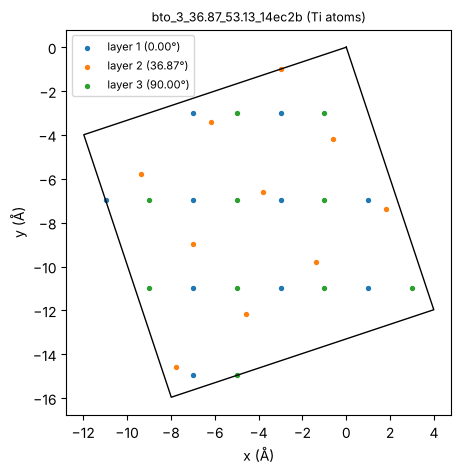

In [20]:
import matplotlib.pyplot as plt

built = build_atoms(trilayer)
fig, ax = plt.subplots(figsize=(5, 5))
for layer, group in built.atoms[built.atoms["type"] == "Ti"].groupby("layer"):
    ax.scatter(group["x"], group["y"], s=8, label=f"layer {layer + 1} ({trilayer.layer_rotations[layer]:.2f}°)")
a1, a2 = trilayer.lattice_vectors
outline = np.array([[0, 0], a1, a1 + a2, a2, [0, 0]])
ax.plot(outline[:, 0], outline[:, 1], "k-", lw=1)
ax.set_aspect("equal"); ax.set_xlabel("x (Å)"); ax.set_ylabel("y (Å)"); ax.legend(fontsize=8)
ax.set_title(f"{trilayer_id} (Ti atoms)", fontsize=9)
plt.show()

In [21]:
from MLM.gui import py3dmol_view, viewer_atoms

py3dmol_view(viewer_atoms(built, repeat=2), colour_by="layer", view="perspective",
             cell=built.cell * np.array([[2], [2], [1]]), width=600, height=420).show()

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

## 11. Recipes, schema versions, reproducibility, command line

A recipe is a small YAML file. `schema_version` lets older files keep loading (and keep their
id) when the format changes:

In [22]:
print((run_dir / "yamls" / f"{trilayer_id}.yaml").read_text())

id: bto_3_36.87_53.13_14ec2b
level: 2
n_layers: 3
material: [bto, bto, bto]
parents: [bto_2_36.87_9ef604, bto_1_406932]
twist: 53.12999999998962
lattice_vectors:
- [-11.971137285300001, -3.9903790951]
- [3.9903790951, -11.971137285300001]
angle_between_vectors: 90.0
residual: 2.278952290352647e-12
cumulative_residual: 1.5939768436640756e-05
source_poscar: [moire_structures/bto/bto_1-layer.vasp, moire_structures/bto/bto_1-layer.vasp,
  moire_structures/bto/bto_1-layer.vasp]
units: angstrom
twist_sequence: [36.87000000000003, 53.12999999998962]
layer_rotations: [0.0, 36.87000000000003, 89.99999999998965]
layer_residuals: [0.0, 2.2542236704043507e-05, 2.278952290352647e-12]
coefficients:
  lower:
  - [1, 1]
  - [-1, 1]
  upper:
  - [-1, 3]
  - [-3, -1]
layer_strains:
- - [0.0, 0.0]
  - [0.0, 0.0]
- - [0.0, 0.0]
  - [0.0, 0.0]
- - [0.0, 0.0]
  - [0.0, 0.0]
strain_energy: null
schema_version: 3



In [23]:
from MLM.structure import migrate_record

added_later = ("schema_version", "layer_strains", "strain_energy")
old_style = {k: v for k, v in trilayer.to_dict().items() if k not in added_later}
upgraded = MoireStructure.from_dict(old_style)   # migrate_record runs inside from_dict
print("a version-1 dict loads:", upgraded == trilayer, "| same id:", upgraded.id == trilayer.id,
      "| migrated to version", migrate_record(old_style)["schema_version"])

a version-1 dict loads: True | same id: True | migrated to version 3


Each run also stores its job as `stack_spec.yaml`; the same job runs from the command line.
The `mlm` command (also `python -m MLM`) has `run`, `find`, `show`, `write`, `check` and `gui`:

In [24]:
print((run_dir / "stack_spec.yaml").read_text()[:600], "...")

name: bto_trilayer_w1
output_dir: runs/feature_tour/bto_trilayer_w1
layers:
- poscar: moire_structures/bto/bto_1-layer.vasp
  material: bto
- poscar: moire_structures/bto/bto_1-layer.vasp
  material: bto
- poscar: moire_structures/bto/bto_1-layer.vasp
  material: bto
search:
  default:
    degmin: 1.0
    degmax: 45.0
    degstep: 0.01
    dtol: 0.0005
    nmin: -10
    nmax: 10
    goodangles:
    - 90.0
    dedupe: true
    keep_supercells: false
    angle_cluster_tol: null
    strain_mode: isotropic
    strain_residual_tol: 1.0e-06
    scanner: fast
    merge_equivalent_twists: none
    inc ...


In [25]:
!mlm find {run_dir} --n-layers 3 --passed yes --max-cell-area 3000 --limit 5
!mlm check {run_dir} {trilayer_id}

                      id  n_layers  twist  angle_between_vectors     residual  cumulative_residual  max_layer_residual  max_strain   cell_area  passed_filter
bto_3_36.87_53.13_14ec2b         3  53.13                   90.0 2.278952e-12             0.000016            0.000023         0.0  159.231253           True
bto_3_22.62_53.13_169a28         3  53.13                   90.0 1.835976e-05             0.000034            0.000076         0.0 1035.003146           True
bto_3_36.87_16.26_872cd4         3  16.26                   90.0 3.564241e-05             0.000036            0.000036         0.0  398.078133           True
bto_3_22.62_30.51_105817         3  30.51                   90.0 5.747165e-05             0.000057            0.000076         0.0 1035.003146           True
bto_3_22.62_14.25_1ab784         3  14.25                   90.0 5.747165e-05             0.000057            0.000076         0.0 1035.003146           True

22 matching structure(s)


checks passed: 210 atoms, composition Ba60O120Ti30
  min_distance: 1.8418 Å
  min_interlayer_distance: 5.9497 Å
  space_group: P2 (3)


## 12. The graphical interface

The same features with buttons: stack the layers, set a twist range per interface, plan, run
(with progress, Stop and Resume), browse results, view structures in 3D and export them.
`mlm gui` opens it as a web page; in a notebook:

In [26]:
from MLM.gui import MLMApp

app = MLMApp(runs_dir=TOUR)   # its Results tab can open every run of this tour
app.display()

## Where to go next

- `notebooks/moire_stack_explorer.ipynb` — your own stack in one input cell, with worked
  examples (rigid and strained PTO/STO).
- `docs/IMPLEMENTATION_NOTES.md` — the API with examples and measured numbers;
  `docs/DESIGN.md` — conventions and decisions.